In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
thu_muc_goc = Path.cwd()
if not (thu_muc_goc / "src").exists():
    thu_muc_goc = thu_muc_goc.parent
if str(thu_muc_goc) not in sys.path:
    sys.path.insert(0, str(thu_muc_goc))

from src.du_lieu import doc_du_lieu
from src.danh_gia import danh_gia_mo_hinh
from src.luu_ket_qua import luu_bang_ket_qua


In [2]:
train_data, test_data, phim = doc_du_lieu(thu_muc_goc)
print("Train:", train_data.shape)
print("Test:", test_data.shape)

Train: (800167, 4)
Test: (200042, 4)


In [3]:
from src.matrix_factorization import huan_luyen_bpr, goi_y_mf
from src.luu_ket_qua import luu_mo_hinh, doc_mo_hinh

mo_hinh = huan_luyen_bpr(
    train_data,
    tiem_an=50,
    lr=0.01,
    l2=0.01,
    epoch=15,
    random_state=42,
)

Epoch 1/15 | BPR loss: 0.6949
Epoch 2/15 | BPR loss: 0.6937
Epoch 3/15 | BPR loss: 0.6872
Epoch 4/15 | BPR loss: 0.6420
Epoch 5/15 | BPR loss: 0.5210
Epoch 6/15 | BPR loss: 0.4229
Epoch 7/15 | BPR loss: 0.3777
Epoch 8/15 | BPR loss: 0.3532
Epoch 9/15 | BPR loss: 0.3409
Epoch 10/15 | BPR loss: 0.3307
Epoch 11/15 | BPR loss: 0.3250
Epoch 12/15 | BPR loss: 0.3179
Epoch 13/15 | BPR loss: 0.3132
Epoch 14/15 | BPR loss: 0.3081
Epoch 15/15 | BPR loss: 0.3033


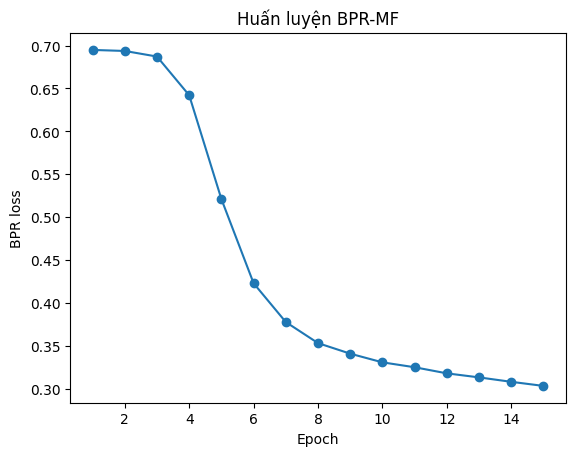

In [4]:
lich_su = mo_hinh["lich_su"]
plt.plot(range(1, len(lich_su) + 1), lich_su, marker="o")
plt.xlabel("Epoch")
plt.ylabel("BPR loss")
plt.title("Huấn luyện BPR-MF")
plt.show()

In [5]:
bang_goi_y = goi_y_mf(mo_hinh, ma_nguoi_dung=1, so_phim=10)
display(bang_goi_y.merge(phim, on="movie_id", how="left"))

,movie_id,score,title,genres
0,2858,3.072055,American Beauty (1999),Comedy|Drama
1,1196,3.004483,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Drama|Sci-Fi|War
2,1210,2.972250,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Romance|Sci-Fi|War
3,593,2.971725,"Silence of the Lambs, The (1991)",Drama|Thriller
4,1617,2.884687,L.A. Confidential (1997),Crime|Film-Noir|Mystery|Thriller
5,1198,2.831684,Raiders of the Lost Ark (1981),Action|Adventure
6,2396,2.795493,Shakespeare in Love (1998),Comedy|Romance
7,589,2.791483,Terminator 2: Judgment Day (1991),Action|Sci-Fi|Thriller
8,318,2.782040,"Shawshank Redemption, The (1994)",Drama
9,608,2.777805,Fargo (1996),Crime|Drama|Thriller


In [6]:
duong_dan = thu_muc_goc / "models/mo_hinh_bpr.joblib"
luu_mo_hinh(mo_hinh, duong_dan)
mo_hinh_da_luu = doc_mo_hinh(duong_dan)
print("Đã lưu và đọc lại:", duong_dan.name)

Đã lưu và đọc lại: mo_hinh_bpr.joblib


In [7]:
ket_qua, chi_tiet = danh_gia_mo_hinh(goi_y_mf, mo_hinh_da_luu, test_data, k=10)
bang_ket_qua = pd.DataFrame([ket_qua])
bang_ket_qua.insert(0, "model", "BPR-MF")
display(bang_ket_qua)
luu_bang_ket_qua(bang_ket_qua, thu_muc_goc / "reports/tables/04_bpr.csv")
luu_bang_ket_qua(chi_tiet, thu_muc_goc / "reports/chi_tiet/04_bpr.csv")

,model,Precision@10,Recall@10,F1@10,NDCG@10,evaluated_users,evaluated_rows,dropped_rows
0,BPR-MF,0.166633,0.096824,0.099204,0.192765,5994,200016,26
